# 07 - Metrics Summary

A clean results page for the trained DHGNN. Reports the two headline metrics on the held-out data:

1. **Cell fate accuracy**

3. **Lineage-coherence** of the learned embeddings (silhouette + k-NN purity) vs. a raw-feature baseline.

In [1]:
import os
import sys
import json

import numpy as np
import torch

sys.path.insert(0, os.path.abspath('..'))
from dhgnn_lib.cell_universe import CellUniverse
from dhgnn_lib import hyperedges, incidence, node_features, labels, metrics, visualization
from dhgnn_lib.dhgnn_model import DHGNNModel

RAW, OUT, CK = '../raw_dataset', '../output_tables', '../checkpoints'
universe = CellUniverse.build(RAW, OUT)
nfb = node_features.NodeFeatureBuilder(RAW, universe)
store = hyperedges.HyperedgeStore(RAW, OUT, universe)
fate = labels.fate_labels(universe)
N = len(universe)

meta = json.load(open(os.path.join(CK, 'model_meta.json')))
model = DHGNNModel(num_features=meta['num_features'], hidden_dim=meta['hidden_dim'], num_layers=meta['num_layers'])
model.load_state_dict(torch.load(os.path.join(CK, 'dhgnn_model.pt')))
model.eval()

# reproduce the cell-disjoint fate split (seed 0) used in training
np.random.seed(0)
FE = torch.zeros(N, dtype=torch.bool)
FE[np.random.permutation(N)[: N // 5]] = True
tps = store.timepoints
val_tps = tps[int(len(tps) * 0.8):]
print(f'N={N} cells | {len(val_tps)} validation timepoints | held-out fate cells={int(FE.sum())}')

N=1625 cells | 30 validation timepoints | held-out fate cells=325


## Metric 1 - Cell fate accuracy (held-out cells)

In [2]:
def _static(): return {'lineage': store.lineage(), 'functional': store.functional()}

P, T = [], []
with torch.no_grad():
    for t in val_tps:
        x = nfb.build(t); p = x[:, 5].bool()
        b = incidence.assemble(N, store.spatial(t), store.lineage(), store.functional())
        o = model(x, b, universe=universe, present_mask=p, static_sets=_static(), recluster=True)
        em = p & FE
        if em.sum():
            P.append(o['fate_logits'][em].argmax(-1)); T.append(fate[em])
fate_acc = (torch.cat(P) == torch.cat(T)).float().mean().item()
print(f'Cell fate accuracy (held-out cells): {fate_acc:.3f}')

Cell fate accuracy (held-out cells): 0.958


## Metric 2 - Lineage-coherence (learned embeddings vs raw features)

In [3]:
t = tps[-1]
x = nfb.build(t); p = x[:, 5].bool()
b = incidence.assemble(N, store.spatial(t), store.lineage(), store.functional())
with torch.no_grad():
    o = model(x, b, universe=universe, present_mask=p, static_sets=_static(), recluster=True)

idx = torch.nonzero(p).flatten()
y = fate[idx].numpy(); emb = o['embeddings'][idx].numpy(); raw = x[idx].numpy()
unk = labels.FATE_NAMES.index('unknown'); keep = y != unk
y, emb, raw = y[keep], emb[keep], raw[keep]
vc = {c: (y == c).sum() for c in np.unique(y)}; g = np.array([vc[c] >= 5 for c in y])
y, emb, raw = y[g], emb[g], raw[g]

emb_sil, emb_knn = metrics.lineage_coherence(emb, y)
raw_sil, raw_knn = metrics.lineage_coherence(raw, y)
print(f'Lineage-coherence @ t={t}  (n={len(y)} founder cells)')
print(f'  learned embeddings: silhouette={emb_sil:+.3f}  kNN-purity={emb_knn:.3f}')
print(f'  raw features      : silhouette={raw_sil:+.3f}  kNN-purity={raw_knn:.3f}')

Lineage-coherence @ t=190  (n=360 founder cells)
  learned embeddings: silhouette=+0.683  kNN-purity=0.977
  raw features      : silhouette=-0.151  kNN-purity=0.721


## Summary

In [4]:
print('='*46)
print('DHGNN - FINAL METRICS')
print('='*46)
print(f'{"Cell fate accuracy (held-out)":36s} {fate_acc:6.3f}')
print(f'{"Lineage-coherence  silhouette":36s} {emb_sil:+6.3f}   (raw {raw_sil:+.3f})')
print(f'{"Lineage-coherence  kNN-purity":36s} {emb_knn:6.3f}   (raw {raw_knn:.3f})')

DHGNN - FINAL METRICS
Cell fate accuracy (held-out)         0.958
Lineage-coherence  silhouette        +0.683   (raw -0.151)
Lineage-coherence  kNN-purity         0.977   (raw 0.721)


## Metrics at a glance (2D bar chart)

Both headline metrics in one view. **Fate accuracy** is the supervised score on held-out cells (no baseline). **Lineage silhouette** and **kNN-purity** compare the DHGNN's **learned** embeddings against the **raw features** baseline — the gap is the structure the model adds. Note the scales differ (accuracy and kNN-purity are 0-1; silhouette is -1..1).

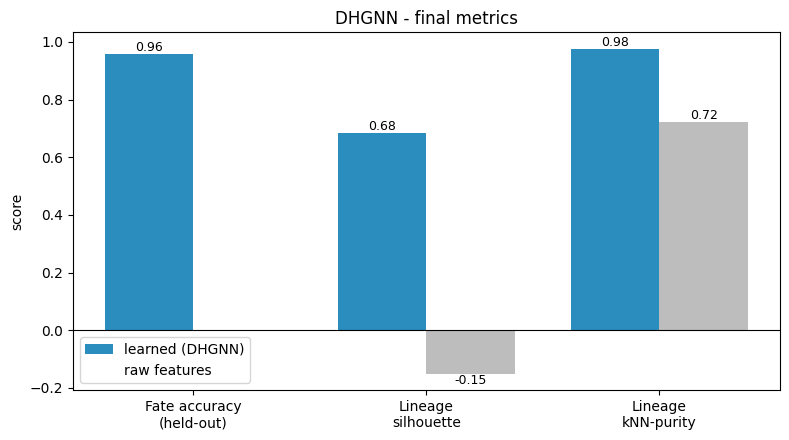

In [5]:
fig = visualization.plot_metrics_summary(fate_acc, emb_sil, emb_knn, raw_sil, raw_knn)
import matplotlib.pyplot as plt
plt.show()